# Лабораторная работа № 4. Кластеризация
М.А. Мотовилов, группа 4415, вариант 4. ГУАП, 2026.

Цель — изучить k-means и агломеративную кластеризацию на искусственных данных
и данных о кредитах. Выполнены обе обязательные части методички.
Вариант 4 принят по подтверждённому распределению в материалах ЛР3.
Дополнительные задания выдаются после защиты и в обязательный объём не входят.

Файл `bank_loan_default.csv` должен лежать рядом с ноутбуком (в Colab — загрузить
его в текущую папку). Зависимости: numpy, pandas, matplotlib, seaborn,
scipy, scikit-learn. Ячейки выполнять сверху вниз. Seed = 42.
Выходные файлы создаются в `utility/results` и `utility/figures`.

In [184]:
# 01. Импорт и вспомогательные функции
from pathlib import Path
import json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, scipy
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, adjusted_rand_score, adjusted_mutual_info_score,
    homogeneity_score, completeness_score, v_measure_score,
    fowlkes_mallows_score)
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree

SEED = 42
ROOT = Path.cwd()
RES, FIG = ROOT / 'utility/results', ROOT / 'utility/figures'
RES.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid', font='DejaVu Sans')
pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 4)
def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()
def quality(X, labels, y=None):
    out = {'silhouette': silhouette_score(X, labels)}
    if y is not None:
        out.update(ARI=adjusted_rand_score(y, labels),
                   AMI=adjusted_mutual_info_score(y, labels),
                   FMI=fowlkes_mallows_score(y, labels),
                   homogeneity=homogeneity_score(y, labels),
                   completeness=completeness_score(y, labels),
                   V_measure=v_measure_score(y, labels))
    return out

Python 3.14.9 | pandas 3.0.3 | sklearn 1.9.1 | scipy 1.18.1

## 1 Искусственные данные
### 1.1 Генерация и стандартизация
Функция сохранена из методички: три группы с центрами (3, 3), (6, 9), (9, 3),
разный масштаб осей. Выбрано n = 150 объектов в группе, всего 450.
StandardScaler вычитает среднее и делит на стандартное отклонение (ddof = 0).
Преобразование обучается на всей выборке: задача описательная, тестовая выборка
и прогноз будущих объектов здесь не требуются.

Первые пять объектов искусственной выборки в исходных координатах.

Проверка стандартизации: средние близки к 0, стандартные отклонения равны 1.

In [185]:
# 02. Генерация по методичке
def make_data(n, seed):
    np.random.seed(seed)
    shift_matrix = np.array([[3, 3], [6, 9], [9, 3]])
    data = np.random.randn(3, 2, n) + shift_matrix.reshape((3, 2, 1))
    data = np.swapaxes(data, 1, 2).reshape((-1, 2))
    data *= np.array([[20, 0.5]])
    df = pd.DataFrame({'x': data[:, 0], 'y': data[:, 1]}, columns=['x', 'y'])
    return df.sample(frac=1.0)

synthetic = make_data(150, SEED)
synthetic_scaler = StandardScaler()
Xs = synthetic_scaler.fit_transform(synthetic)
display(synthetic.head())
display(pd.DataFrame({'среднее': Xs.mean(axis=0), 'стд. ddof=0': Xs.std(axis=0)},
                     index=synthetic.columns))
synthetic.to_csv(RES / 'synthetic.csv', index_label='source_row')

,x,y
371,138.5322,2.2047
103,43.9545,2.0162
259,130.2888,4.2895
432,188.1651,1.2553
385,194.2600,1.6171


,среднее,стд. ddof=0
x,1.1448e-16,1.0
y,-9.4739e-17,1.0


### 1.2 k-means для 2, 3 и 4 кластеров
Алгоритм минимизирует сумму квадратов расстояний до центров (inertia).
Используются k-means++, n_init = 20, random_state = 42.
На графиках показаны исходные единицы; центры возвращены из стандартизованного
пространства через inverse_transform. Метки кластеров — условные номера.

Разбиения при k = 2, 3 и 4; чёрные кресты — центры групп.

Качество трёх разбиений: чем выше силуэт, тем лучше отделены группы.

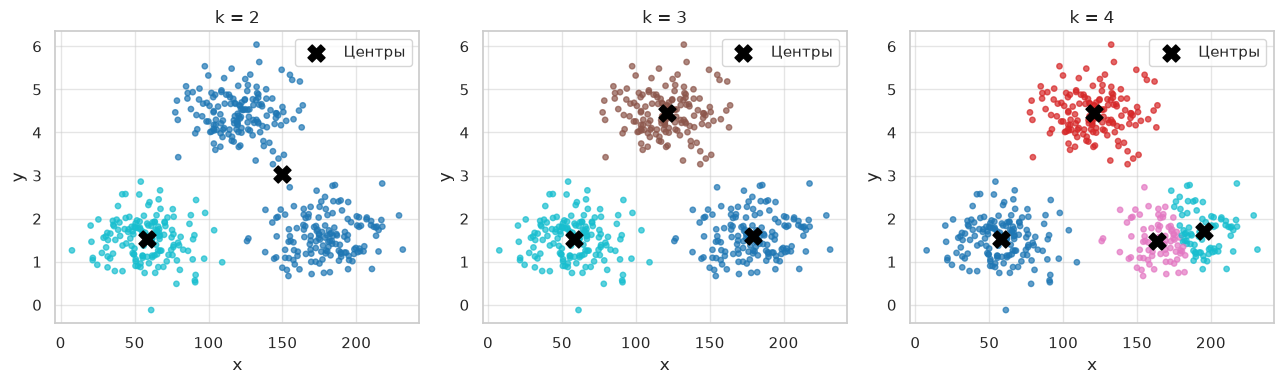

,k,inertia,silhouette
0,2,494.1837,0.4876
1,3,111.1488,0.7065
2,4,96.4855,0.5705


In [186]:
# 03. Разбиения и центры
synthetic_models = {}
rows = []
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, k in zip(axes, [2, 3, 4]):
    model = KMeans(n_clusters=k, n_init=20, random_state=SEED)
    labels = model.fit_predict(Xs)
    synthetic_models[k] = model
    rows.append({'k': k, 'inertia': model.inertia_, **quality(Xs, labels)})
    ax.scatter(synthetic.x, synthetic.y, c=labels, cmap='tab10', s=15, alpha=.7)
    centers = synthetic_scaler.inverse_transform(model.cluster_centers_)
    ax.scatter(centers[:, 0], centers[:, 1], c='black', marker='X', s=150, label='Центры')
    ax.set(xlabel='x', ylabel='y', title=f'k = {k}')
    ax.legend()
savefig('01_synthetic_clusters')
synthetic_metrics = pd.DataFrame(rows)
display(synthetic_metrics)
synthetic_metrics.to_csv(RES / 'synthetic_metrics.csv', index=False)

### 1.3 Метод локтя
Для k от 1 до 10 считаем inertia; силуэт определён при k ≥ 2.
Inertia убывает при росте k сама по себе: нужен перегиб кривой и согласование
с силуэтом, а не минимальное значение inertia.

Выбор k: слева локоть inertia, справа силуэт. Предпочтительно k = 3.

Численные результаты подбора k; при k = 1 силуэт не определён.

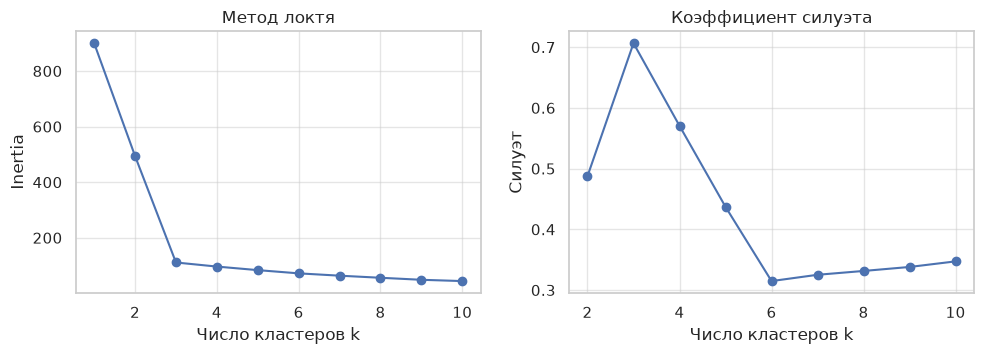

,k,inertia,silhouette
0,1,900.0000,NaN
1,2,494.1837,0.4876
2,3,111.1488,0.7065
3,4,96.4855,0.5705
4,5,83.6785,0.4371
5,6,72.0632,0.3148
6,7,63.7044,0.3252
7,8,56.2042,0.3315
8,9,48.9223,0.3381
9,10,44.2900,0.3473


In [187]:
# 04. Локоть и силуэт на искусственных данных
rows = []
for k in range(1, 11):
    m = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Xs)
    rows.append({'k': k, 'inertia': m.inertia_,
                 'silhouette': silhouette_score(Xs, m.labels_) if k > 1 else np.nan})
synthetic_search = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
axes[0].plot(synthetic_search.k, synthetic_search.inertia, 'o-')
axes[0].set(xlabel='Число кластеров k', ylabel='Inertia', title='Метод локтя')
axes[1].plot(synthetic_search.k, synthetic_search.silhouette, 'o-')
axes[1].set(xlabel='Число кластеров k', ylabel='Силуэт', title='Коэффициент силуэта')
savefig('02_synthetic_selection')
display(synthetic_search)
synthetic_search.to_csv(RES / 'synthetic_search.csv', index=False)
best_syn = int(synthetic_search.loc[synthetic_search.silhouette.idxmax(), 'k'])

Максимальный силуэт получен при **k = 3**. При k = 2 объединяются разные сгенерированные группы; при k = 4 одна из групп дробится. Кривая локтя позволяет проверить выбор k = 3.

## 2 Кредитные данные, вариант 4
### 2.1 Загрузка и аудит
`bank_loan_default.csv`: возраст, годовой доход (USD), тип занятости, образование,
сумма кредита (USD), ставка (%), срок (месяцы), кредитный скор,
число открытых счетов, просрочка 30 дней и тип жилья.
`Default` — известный класс (1 — дефолт, 0 — нет), используется только для
цвета на исходных диаграммах, внешних метрик и интерпретации после обучения.
В матрицу признаков, стандартизацию и выбор k он не включается.

Первые пять строк кредитной выборки до обработки.

Аудит столбцов: типы данных, число пропусков и уникальных значений.

Описательная статистика числовых признаков в исходных единицах.

In [188]:
# 05. Загрузка и проверки
raw = pd.read_csv(ROOT / 'bank_loan_default.csv')
numeric = ['age', 'annual_income', 'loan_amount', 'interest_rate_pct',
           'term_months', 'credit_score', 'num_open_accounts']
categorical = ['employment_type', 'education', 'delinquency_30d', 'residence_type']
audit = pd.DataFrame({'тип': raw.dtypes.astype(str), 'пропуски': raw.isna().sum(),
                      'уникальных': raw.nunique()})
display(raw.head())
display(audit)
display(raw[numeric].describe().T)
assert set(raw.Default.unique()) <= {0, 1}
assert np.isfinite(raw[numeric].to_numpy()).all()
assert not raw.isna().any().any()
assert not raw.duplicated().any()
valid = (raw.age.between(18, 100) & (raw.annual_income > 0) &
         (raw.loan_amount > 0) & (raw.interest_rate_pct > 0) &
         raw.term_months.isin([24, 36, 48, 60, 72]) &
         raw.credit_score.between(300, 850) & (raw.num_open_accounts >= 0))
assert valid.all(), 'Найдены недопустимые значения: требуется проверка'
data = raw.copy()
y = data['Default'].copy()
X = data[numeric].copy()
audit.to_csv(RES / 'data_audit.csv', index_label='признак')
X.describe().T.to_csv(RES / 'descriptive.csv', index_label='признак')

,age,annual_income,employment_type,education,loan_amount,interest_rate_pct,term_months,credit_score,num_open_accounts,delinquency_30d,residence_type,Default
0,42,57272.0,Self-Employed,Masters,8516.0,5.85,48,730.0,10,No,Own,0
1,51,45786.0,Salaried,Masters,13760.0,9.97,36,677.0,7,No,Mortgage,0
2,69,42359.0,Salaried,Bachelors,2569.0,13.75,48,624.0,2,No,Own,0
3,65,50709.0,Self-Employed,Masters,13204.0,8.70,48,698.0,3,No,Rent,0
4,30,46272.0,Salaried,HS,7700.0,7.53,48,532.0,7,No,Rent,0


,тип,пропуски,уникальных
age,int64,0,54
annual_income,float64,0,2939
employment_type,str,0,3
education,str,0,4
loan_amount,float64,0,2801
interest_rate_pct,float64,0,1214
term_months,int64,0,5
credit_score,float64,0,353
num_open_accounts,int64,0,15
delinquency_30d,str,0,2


,count,mean,std,min,25%,50%,75%,max
age,3041.0,47.0888,15.6001,21.0,34.00,47.0,60.00,74.000
annual_income,3041.0,45746.1828,23572.5062,7433.0,28741.00,40826.0,57428.00,237129.000
loan_amount,3041.0,10683.3093,7384.8668,1016.0,5540.00,8797.0,13464.00,69139.000
interest_rate_pct,3041.0,9.4363,3.5235,1.9,7.15,9.3,11.44,33.888
term_months,3041.0,47.6962,13.8832,24.0,36.00,48.0,60.00,72.000
credit_score,3041.0,681.2634,73.0071,417.0,632.00,683.0,733.00,850.000
num_open_accounts,3041.0,4.5459,2.1760,0.0,3.00,4.0,6.00,14.000


Размер: (3041, 12) | Полных дубликатов: 0

Классы: {0: 2421, 1: 620}
SHA256: ac9181e55be37a2436df8eff1a5fb3fe09c6bbb253540a1ff5e3ed4caf1c90af

### 2.2 Предобработка и исходные зависимости
Пропуски, дубликаты и допустимость значений проверены явными утверждениями.
Если проверки не проходят на другом файле, выполнение остановится для анализа.
Большие доходы и суммы кредитов сохранены: нет оснований считать их ошибками.
IQR используется для диагностики, а не для автоматического удаления клиентов.
Базовая кластеризация использует 7 числовых признаков; срок кредита трактуется
как длительность. Четыре категориальных признака сохранены для описания групп,
их кодирование относится к дополнительным заданиям 1–2 методички.
Матрица рассеяния содержит все 7 числовых признаков и все объекты.

Число значений за IQR-границами; это диагностика, строки не удаляются.

Попарные связи признаков; цвет — Default, который не входит в обучение.

,Число значений вне IQR-границ
age,0
annual_income,93
loan_amount,153
interest_rate_pct,41
term_months,0
credit_score,11
num_open_accounts,29


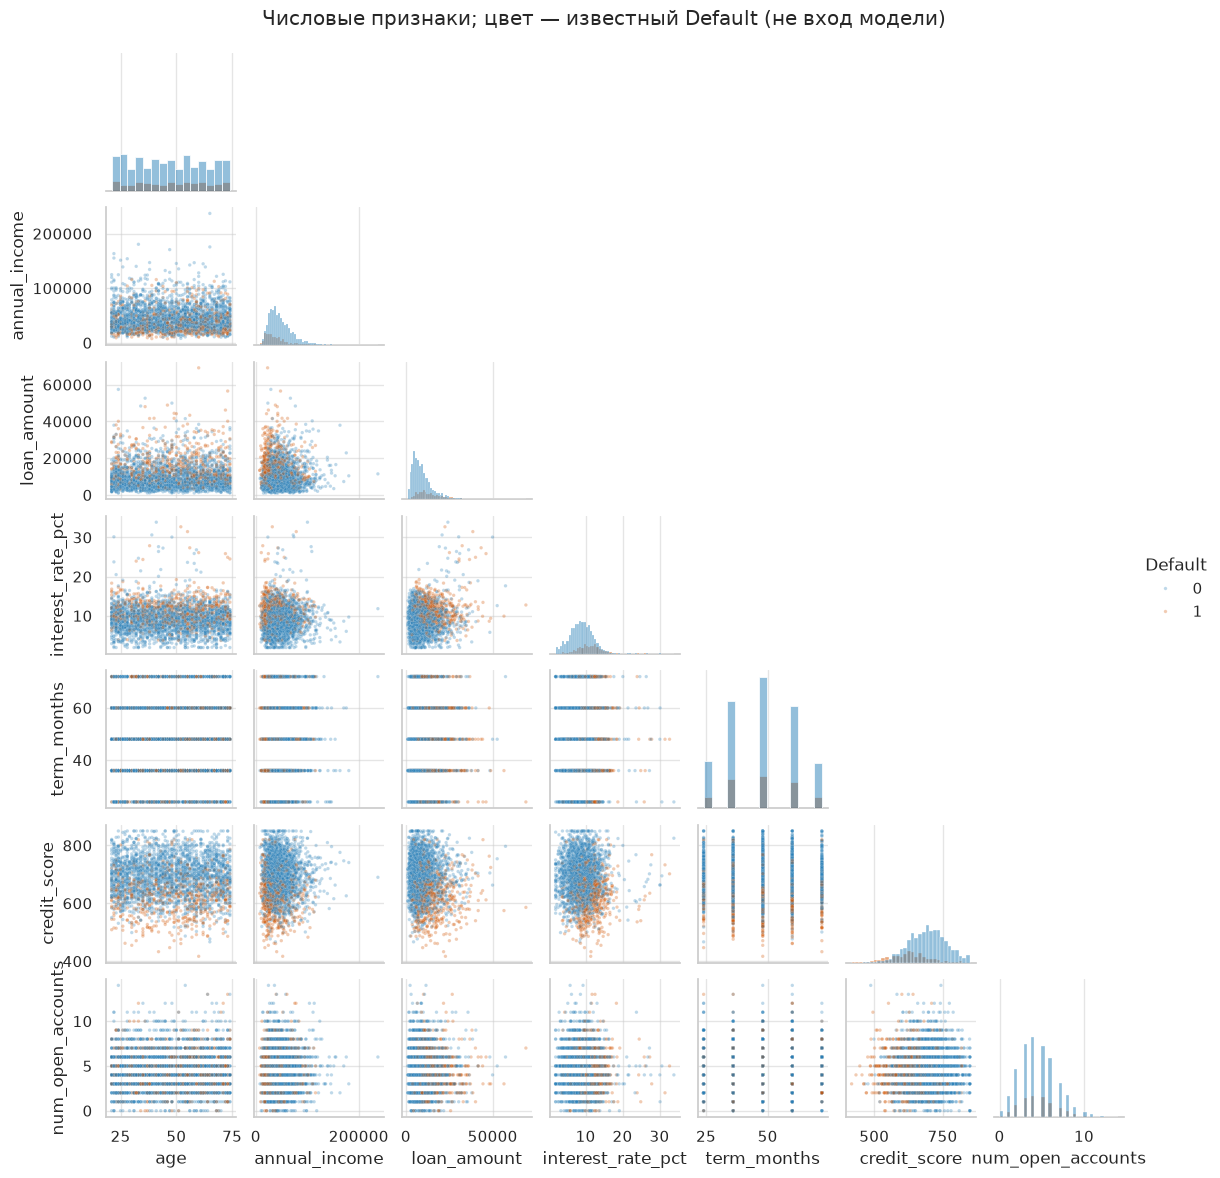

In [189]:
# 06. Матрица рассеяния и диагностика распределений
q1, q3 = X.quantile(.25), X.quantile(.75)
iqr = q3 - q1
outlier_counts = ((X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)).sum()
display(outlier_counts.rename('Число значений вне IQR-границ').to_frame())
outlier_counts.to_csv(RES / 'iqr_diagnostics.csv', index_label='признак')
g = sns.pairplot(data[numeric + ['Default']], hue='Default',
                 vars=numeric, diag_kind='hist', corner=True,
                 plot_kws={'s': 6, 'alpha': .3, 'rasterized': True}, height=1.65,
                 palette={0: '#2980b9', 1: '#d35400'})
g.fig.suptitle('Числовые признаки; цвет — известный Default (не вход модели)', y=1.02)
g.savefig(FIG / '03_pairplot.png', dpi=150, bbox_inches='tight')
plt.show()

### 2.3 Стандартизация и выбор k для k-means
Масштабирование обязательно из-за различия единиц (USD, месяцы, проценты).
StandardScaler обучается только на X. Сравниваются k = 2…10; k = 1 нужен
для локтя. Основной критерий — максимум внутреннего силуэта. Внешние метрики и доля дефолта не используются для выбора.
Силуэт вычисляется точно на всех объектах, без случайной подвыборки.

Проверка StandardScaler для семи числовых признаков.

Метрики k-means для разных k; число групп выбирается по максимуму силуэта.

Локоть и силуэт на кредитах: результаты для k = 2 и k = 3 очень близки.

,среднее,стд. ddof=0
age,9.3462e-18,1.0
annual_income,-4.9652e-17,1.0
loan_amount,5.1404e-17,1.0
interest_rate_pct,2.1029e-17,1.0
term_months,7.3601e-17,1.0
credit_score,-4.8366e-16,1.0
num_open_accounts,1.0281e-16,1.0


,k,inertia,silhouette
0,1,21287.0000,NaN
1,2,18973.3235,0.1178
2,3,17159.1392,0.1184
3,4,15864.0020,0.1168
4,5,14815.5388,0.1108
5,6,13972.8236,0.1086
6,7,13229.2231,0.1105
7,8,12719.6119,0.1161
8,9,12210.9940,0.1111
9,10,11792.6616,0.1105


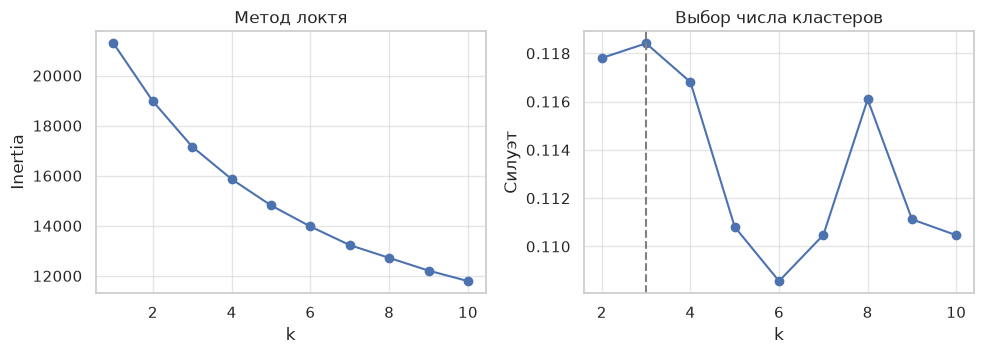

In [190]:
# 07. StandardScaler и подбор k
scaler = StandardScaler()
Z = scaler.fit_transform(X)
assert 'Default' not in X.columns and X.shape[1] == 7
assert np.allclose(Z.mean(axis=0), 0, atol=1e-10)
assert np.allclose(Z.std(axis=0), 1, atol=1e-10)
scale_check = pd.DataFrame({'среднее': Z.mean(axis=0), 'стд. ddof=0': Z.std(axis=0)}, index=numeric)
display(scale_check)
scale_check.to_csv(RES / 'scale_check.csv', index_label='признак')
models, rows = {}, []
for k in range(1, 11):
    model = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
    models[k] = model
    rows.append({'k': k, 'inertia': model.inertia_,
                 **(quality(Z, model.labels_) if k > 1 else {})})
search = pd.DataFrame(rows)
best_k = int(search.loc[search.silhouette.idxmax(), 'k'])
km = models[best_k]
labels_km = km.labels_
display(search)
search.to_csv(RES / 'kmeans_search.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
axes[0].plot(search.k, search.inertia, 'o-')
axes[0].set(xlabel='k', ylabel='Inertia', title='Метод локтя')
axes[1].plot(search.k, search.silhouette, 'o-')
axes[1].axvline(best_k, color='grey', linestyle='--')
axes[1].set(xlabel='k', ylabel='Силуэт', title='Выбор числа кластеров')
savefig('04_bank_selection')

Выбранное k: 3

### 2.4 Состав кластеров и средние показатели
Средние рассчитаны в исходных единицах по всем числовым признакам.
Для категорий математическое среднее не определено: приведены моды и
полные доли категорий. `default_rate` — характеристика уже полученных групп,
а не вход обучения. В `assignments.csv` сохранены исходные строки и номера
обоих кластеров, чтобы можно было найти любой объект.

Размеры групп: n — число клиентов, default_rate — доля дефолтов от 0 до 1.

Средние числовые признаки каждой группы в исходных единицах.

Наиболее частые значения категориальных признаков в каждой группе.

Центры k-means: отклонения от общего среднего в стандартных отклонениях.

,n,default_rate
cluster,,
0,509,0.5756
1,1319,0.1274
2,1213,0.1311


,age,annual_income,loan_amount,interest_rate_pct,term_months,credit_score,num_open_accounts
cluster,,,,,,,
0,48.3752,42317.2436,22285.1686,11.8035,47.3399,631.1041,4.1866
1,33.5375,46435.3518,8274.9748,9.1214,47.4632,694.4913,4.5042
2,61.2844,46435.6439,8433.7189,8.7853,48.0989,687.9275,4.7420


,employment_type,education,delinquency_30d,residence_type
cluster,,,,
0,Salaried,Bachelors,No,Rent
1,Salaried,Bachelors,No,Rent
2,Salaried,Bachelors,No,Rent


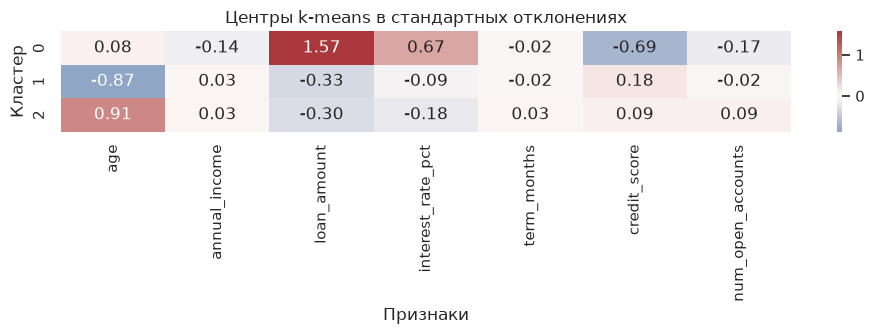

In [191]:
# 08. Профили k-means
def profile(labels, prefix):
    frame = data.assign(cluster=labels)
    means = frame.groupby('cluster')[numeric].mean()
    sizes = frame.groupby('cluster').agg(n=('Default', 'size'), default_rate=('Default', 'mean'))
    modes = frame.groupby('cluster')[categorical].agg(lambda s: s.mode().iloc[0])
    means.to_csv(RES / f'{prefix}_means.csv')
    sizes.to_csv(RES / f'{prefix}_sizes.csv')
    modes.to_csv(RES / f'{prefix}_modes.csv')
    for col in categorical:
        pd.crosstab(frame.cluster, frame[col], normalize='index').to_csv(RES / f'{prefix}_{col}_shares.csv')
    display(sizes)
    display(means)
    display(modes)
    return means, sizes
km_means, km_sizes = profile(labels_km, 'kmeans')
fig, ax = plt.subplots(figsize=(10, 3.5))
sns.heatmap(pd.DataFrame(km.cluster_centers_, columns=numeric), annot=True,
            fmt='.2f', cmap='vlag', center=0, ax=ax)
ax.set(xlabel='Признаки', ylabel='Кластер', title='Центры k-means в стандартных отклонениях')
savefig('05_kmeans_profiles')

**Интерпретация кластеров k-means:**

- Кластер 0: n=509, доля дефолта 57.6%. Основные отличия: loan_amount: 22285.17 (+1.57 σ); credit_score: 631.10 (-0.69 σ); interest_rate_pct: 11.80 (+0.67 σ).

- Кластер 1: n=1319, доля дефолта 12.7%. Основные отличия: age: 33.54 (-0.87 σ); loan_amount: 8274.97 (-0.33 σ); credit_score: 694.49 (+0.18 σ).

- Кластер 2: n=1213, доля дефолта 13.1%. Основные отличия: age: 61.28 (+0.91 σ); loan_amount: 8433.72 (-0.30 σ); interest_rate_pct: 8.79 (-0.18 σ).

### 2.5 Иерархическая агломеративная кластеризация
Используется евклидово расстояние и критерий Ward, минимизирующий прирост
внутрикластерной суммы квадратов. Дендрограмма строится по всем 3041 объектам;
для читаемости показаны последние 30 ветвей (число в скобках — размер ветви).
Для k = 2…10 разрезаем одно и то же полное дерево и выбираем максимум силуэта.
Затем отдельно обучаем AgglomerativeClustering с выбранным k и проверяем
совпадение разбиений через ARI = 1 (номера меток могут различаться).

Метрики разрезов дерева Ward; максимальный силуэт получен при k = 2.

Дерево по всем 3041 клиентам: показаны последние 30 ветвей и разрез на две группы.

Размеры групп: n — число клиентов, default_rate — доля дефолтов от 0 до 1.

Средние числовые признаки каждой группы в исходных единицах.

Наиболее частые значения категориальных признаков в каждой группе.

Размеры групп: n — число клиентов, default_rate — доля дефолтов от 0 до 1.

Средние числовые признаки каждой группы в исходных единицах.

Наиболее частые значения категориальных признаков в каждой группе.

,k,silhouette
0,2,0.1890
1,3,0.0767
2,4,0.0772
3,5,0.0513
4,6,0.0390
5,7,0.0382
6,8,0.0446
7,9,0.0485
8,10,0.0495


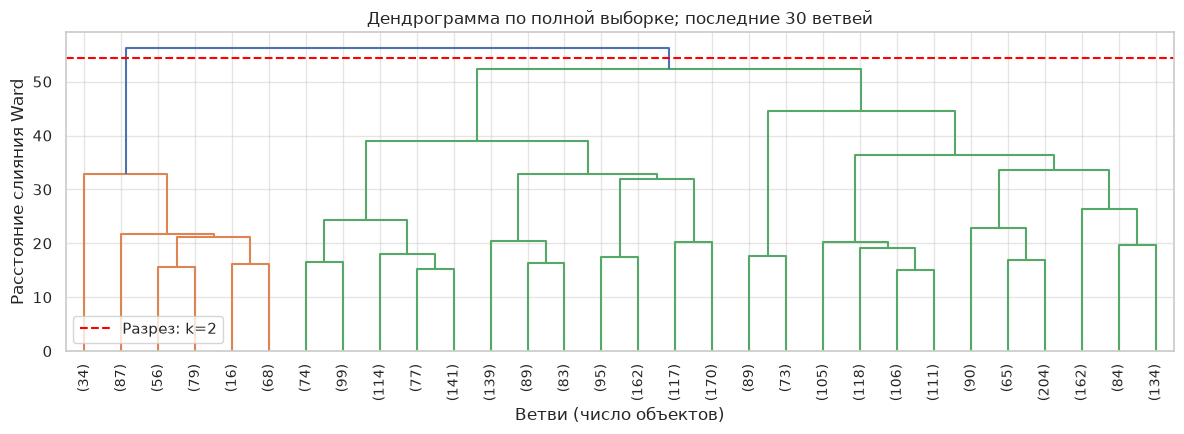

,n,default_rate
cluster,,
0,2701,0.1699
1,340,0.4735


,age,annual_income,loan_amount,interest_rate_pct,term_months,credit_score,num_open_accounts
cluster,,,,,,,
0,47.1055,45617.0111,8934.4499,9.1665,48.0133,685.0855,4.5020
1,46.9559,46772.3382,24576.4541,11.5793,45.1765,650.9000,4.8941


,employment_type,education,delinquency_30d,residence_type
cluster,,,,
0,Salaried,Bachelors,No,Rent
1,Salaried,Bachelors,No,Rent


In [192]:
# 09. Полное дерево Ward, дендрограмма и подбор k
tree = linkage(Z, method='ward', metric='euclidean')
rows = []
for k in range(2, 11):
    lab = cut_tree(tree, n_clusters=k).ravel()
    rows.append({'k': k, **quality(Z, lab)})
ward_search = pd.DataFrame(rows)
best_ward_k = int(ward_search.loc[ward_search.silhouette.idxmax(), 'k'])
ward = AgglomerativeClustering(n_clusters=best_ward_k, linkage='ward', metric='euclidean')
labels_ward = ward.fit_predict(Z)
tree_agreement = adjusted_rand_score(labels_ward, cut_tree(tree, n_clusters=best_ward_k).ravel())
assert np.isclose(tree_agreement, 1)
display(ward_search)
ward_search.to_csv(RES / 'ward_search.csv', index=False)
cut_height = (tree[-best_ward_k, 2] + tree[-best_ward_k + 1, 2]) / 2
fig, ax = plt.subplots(figsize=(12, 4.5))
dendrogram(tree, truncate_mode='lastp', p=30, leaf_rotation=90,
           color_threshold=cut_height, ax=ax)
ax.axhline(cut_height, linestyle='--', color='red', label=f'Разрез: k={best_ward_k}')
ax.set(xlabel='Ветви (число объектов)', ylabel='Расстояние слияния Ward',
       title='Дендрограмма по полной выборке; последние 30 ветвей')
ax.legend()
savefig('06_dendrogram')
ward_means, ward_sizes = profile(labels_ward, 'ward')

Ward: выбрано k = 2 | ARI двух реализаций = 1.0

**Интерпретация кластеров Ward:**

- Кластер 0: n=2701, доля дефолта 17.0%. Основные отличия: loan_amount: 8934.45 (-0.24 σ); interest_rate_pct: 9.17 (-0.08 σ); credit_score: 685.09 (+0.05 σ).

- Кластер 1: n=340, доля дефолта 47.4%. Основные отличия: loan_amount: 24576.45 (+1.88 σ); interest_rate_pct: 11.58 (+0.61 σ); credit_score: 650.90 (-0.42 σ).

### 2.6 Метрики и сравнение
Силуэт (−1…1): больше — лучше.
ARI и AMI корректируются на случайные совпадения (могут быть отрицательными).
FMI, однородность, полнота и V-мера лежат в [0, 1], больше — лучше.
Внешние метрики сравнивают кластеры с Default, но цель кластеризации —
сходство клиентов, а не воспроизведение известных классов.
При разных k и несбалансированных классах отдельные метрики могут расходиться.

### Сравнение выбранных разбиений
В таблице сравниваются k-means при k = 3 и Ward при k = 2. **Silhouette: больше — лучше.** ARI, AMI, FMI, homogeneity, completeness и V_measure сравнивают кластеры с известным Default, который не участвовал в обучении.

### Кластеры в двух проекциях признаков
**Верхний ряд — k-means, нижний — Ward.** Слева показаны годовой доход и сумма кредита, справа — кредитный скор и процентная ставка. Цвет обозначает кластер, а чёрные кресты — средние значения признаков в каждой группе. Номера и цвета кластеров условны: одинаковый цвет у разных методов не гарантирует одинаковый состав группы. Это двумерные проекции разбиений, построенных по семи стандартизованным признакам; оси показаны в исходных единицах. Перекрытие точек в проекции возможно.

### Как качество зависит от числа кластеров
График показывает **силуэт** двух методов при изменении k. Кружки соответствуют k-means, квадраты — Ward. Для силуэта предпочтительны высокие значения. Число кластеров выбиралось по максимуму силуэта: k = 3 для k-means и k = 2 для Ward. Силуэт Ward равен 0,1890, k-means — 0,1184. У k-means при k = 2 значение почти такое же — 0,1178, поэтому выбор трёх групп неоднозначен. Ward предпочтителен по силуэту, но AMI и V-мера выше у k-means: общего превосходства по всем метрикам нет.

метод,k-means,Ward
k,3.0000,2.0000
silhouette,0.1184,0.1890
ARI,0.1104,0.1590
AMI,0.0926,0.0547
FMI,0.5629,0.7782
homogeneity,0.1410,0.0466
completeness,0.0693,0.0673
V_measure,0.0930,0.0551


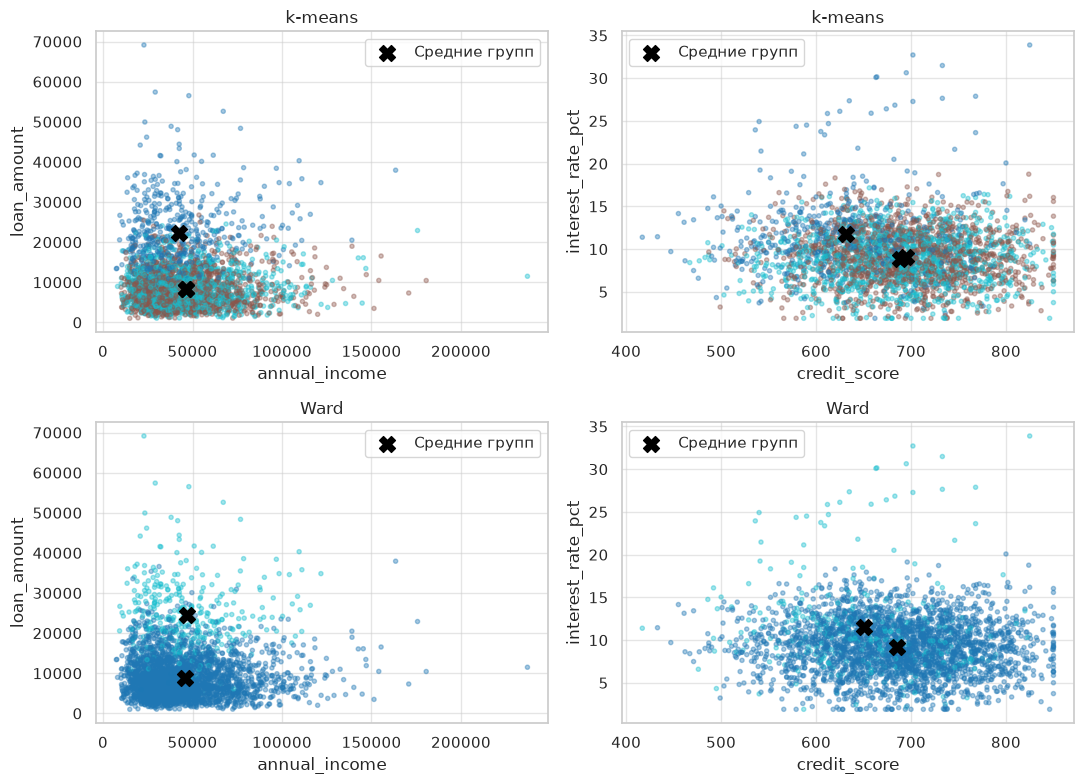

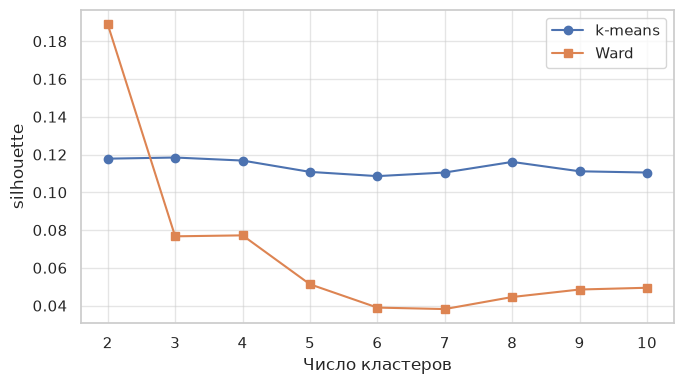

531

In [193]:
# 10. Итоговые метрики, объекты кластеров и две пары признаков
comparison = pd.DataFrame([
    {'метод': 'k-means', 'k': best_k, **quality(Z, labels_km, y)},
    {'метод': 'Ward', 'k': best_ward_k, **quality(Z, labels_ward, y)}
]).set_index('метод')
display(comparison.T)
comparison.to_csv(RES / 'comparison.csv')
assignments = data.assign(cluster_kmeans=labels_km, cluster_ward=labels_ward)
assignments.to_csv(RES / 'assignments.csv', index_label='source_row_0based')
for name, labels in [('kmeans', labels_km), ('ward', labels_ward)]:
    pd.crosstab(y, labels).to_csv(RES / f'{name}_contingency.csv')
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for row, (method, labels) in enumerate([('k-means', labels_km), ('Ward', labels_ward)]):
    for col, (a, b) in enumerate([('annual_income', 'loan_amount'), ('credit_score', 'interest_rate_pct')]):
        ax = axes[row, col]
        ax.scatter(X[a], X[b], c=labels, cmap='tab10', s=9, alpha=.4)
        centers = data.assign(cluster=labels).groupby('cluster')[numeric].mean()
        ax.scatter(centers[a], centers[b], marker='X', c='black', s=130, label='Средние групп')
        ax.set(xlabel=a, ylabel=b, title=method)
        ax.legend()
savefig('07_bank_clusters')
fig, axes = plt.subplots(1, 1, figsize=(7, 4))
for ax, col in [(axes, 'silhouette')]:
    ax.plot(search.k, search[col], 'o-', label='k-means')
    ax.plot(ward_search.k, ward_search[col], 's-', label='Ward')
    ax.set(xlabel='Число кластеров', ylabel=col)
    ax.legend()
savefig('08_method_selection')
summary = {'n': len(data), 'features': numeric, 'categorical': categorical,
           'best_synthetic_k': best_syn, 'best_k': best_k, 'best_ward_k': best_ward_k,
           'tree_agreement': tree_agreement,
           'cluster_agreement': adjusted_rand_score(labels_km, labels_ward),
           'default_rate': float(y.mean()),
           'sha256': hashlib.sha256((ROOT / 'bank_loan_default.csv').read_bytes()).hexdigest()}
(RES / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')

ARI между k-means и Ward: 0.14862333202980282

## 3 Заключение

## Выводы по фактически рассчитанным результатам

Выполнены обе части работы. Искусственная выборка содержит 450 объектов; по силуэту выбрано k=3. В кредитной выборке 3041 заёмщик, 7 числовых признаков. Пропуски, полные дубликаты и недопустимые значения не обнаружены; крайние значения сохранены, применён StandardScaler. Категориальные признаки использованы для описания групп, Default исключён из обучения.

По максимуму силуэта выбраны k=3 для k-means и k=2 для Ward. Силуэт k-means = 0.1184, Ward = 0.1890. Для описательной сегментации по этому критерию предпочтителен Ward. Средние и доли категорий характеризуют каждую группу; различия долей дефолта позволяют описать связь с риском, но не устанавливают причинность.

ARI с известным Default: k-means = 0.1104, Ward = 0.1590. Число кластеров ограничено диапазоном 2–10; слабое совпадение с классами не означает отсутствие сегментации, но ограничивает применение для прогноза дефолта. Различие масштабов устранено стандартизацией, неоднозначность числа групп проверена силуэтом, локтем и дендрограммой. Для прогноза необходима отдельная задача классификации с проверкой на новых данных; удаление крупных кредитов ради улучшения метрик не выполнялось.

## Материалы для сдачи
В ноутбуке сохранены код, Markdown-пояснения, фактические таблицы и графики.
HTML-копия открывается без Jupyter. CSV с принадлежностью каждого клиента
к кластерам находится в `utility/results/assignments.csv`.
Публичную ссылку Colab / Kaggle / GitHub необходимо добавить после размещения
ноутбука и проверить без авторизации. Локальный файл не является публичной ссылкой.

Источник задания: «Лабораторная работа 4. Кластеризация 2026», с. 17–25,
локальный PDF в папке работы. Данные: приложенный `bank_loan_default.csv`.

## 4 Дополнительные задания

### 4.1 Задание 6 — зависимость метрик от числа кластеров

На тех же кредитных данных проверяем k-means при числе кластеров от 2 до 10 включительно. `Z` содержит семь числовых признаков после StandardScaler, а `y` — известные значения Default. В обучение Default не входит: он нужен только для вычисления внешних метрик после получения кластеров.

В цикле `range(2, 11)` каждое значение `k` задаёт новую модель. `fit(Z)` обучает её, `model.labels_` содержит номер кластера каждого клиента. `n_init=20` задаёт 20 запусков с разными начальными центрами; `random_state=SEED` обеспечивает воспроизводимость. Словарь `models` сохраняет модели по числу кластеров.

Функция `quality(Z, model.labels_, y)` возвращает силуэт и шесть внешних метрик. Оператор `**` добавляет эти пары «название — значение» в словарь строки рядом с `k`. Список `rows` преобразуется в таблицу `my_synthetic_search`: название переменной сохранено из вашего кода, но здесь рассматриваются кредитные, а не искусственные данные.

В таблице оставлены все рассчитанные метрики, а на одном графике показаны четыре: silhouette, ARI, AMI и V_measure. Силуэт характеризует компактность и отделённость кластеров без известных классов; ARI, AMI и V-мера сравнивают разбиение с Default. ARI и AMI учитывают случайные совпадения, V-мера объединяет однородность и полноту. Для всех четырёх метрик большее значение соответствует лучшему результату по своему критерию. Перебирать столбец `k` при построении линий не требуется: он задаёт общую ось X.

,k,silhouette,ARI,AMI,FMI,homogeneity,completeness,V_measure
0,2,0.1178,0.2197,0.1747,0.6853,0.2032,0.1535,0.1749
1,3,0.1184,0.1104,0.0926,0.5629,0.1410,0.0693,0.0930
2,4,0.1168,0.0722,0.0775,0.4870,0.1401,0.0540,0.0780
3,5,0.1108,0.0451,0.0611,0.4197,0.1261,0.0409,0.0617
4,6,0.1086,0.0335,0.0550,0.3783,0.1239,0.0359,0.0556
5,7,0.1105,0.0284,0.0556,0.3476,0.1347,0.0356,0.0564
6,8,0.1161,0.0306,0.0562,0.3466,0.1389,0.0359,0.0571
7,9,0.1111,0.0263,0.0582,0.3201,0.1526,0.0367,0.0592
8,10,0.1105,0.0210,0.0549,0.2978,0.1509,0.0343,0.0559


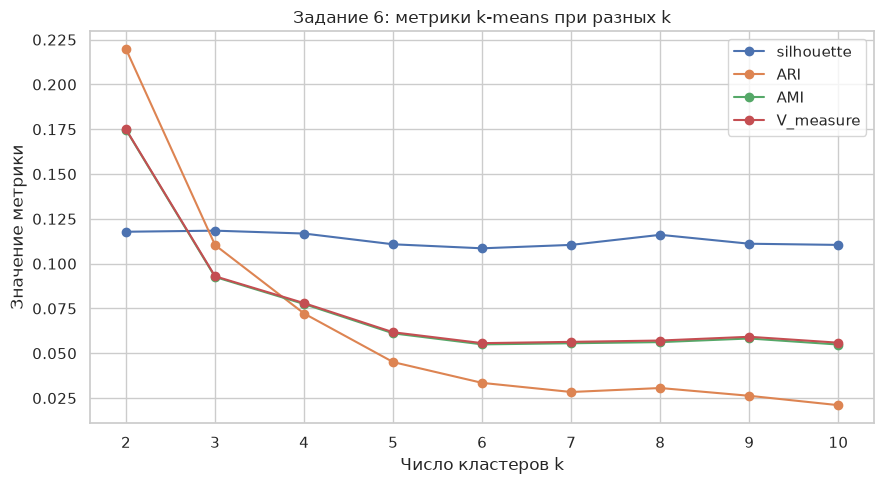

In [12]:
rows = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
    models[k] = model
    rows.append({'k': k, **quality(Z, model.labels_, y)})

my_synthetic_search = pd.DataFrame(rows)
display(my_synthetic_search)

plt.figure(figsize=(9, 5))
for metric in ['silhouette', 'ARI', 'AMI', 'V_measure']:
    plt.plot(my_synthetic_search.k, my_synthetic_search[metric], 'o-', label=metric)
plt.xlabel('Число кластеров k')
plt.ylabel('Значение метрики')
plt.title('Задание 6: метрики k-means при разных k')
plt.xticks(range(2, 11))
plt.legend()
plt.tight_layout()
plt.show()

По рассчитанной таблице максимум силуэта достигается при k = 3 (около 0,1184), но значение при k = 2 почти такое же (около 0,1178). Разница мала, а сами значения указывают на слабую отделённость групп. ARI, AMI и V-мера максимальны при k = 2: примерно 0,2197, 0,1747 и 0,1749 соответственно. При увеличении числа кластеров согласованность с Default в целом снижается, хотя отдельные значения меняются немонотонно.

Таким образом, критерии отвечают на разные вопросы: по внутреннему силуэту выбираем k = 3, а по сходству с двумя известными классами лучше k = 2. В основной работе число кластеров выбирается без использования Default, поэтому сохраняем k = 3. Даже максимум внешних метрик не означает точного восстановления классов дефолта.

### 4.2 Задание 7 — сравнение способов масштабирования

Применим к одним и тем же семи числовым признакам StandardScaler, MinMaxScaler и MaxAbsScaler. StandardScaler вычисляет `(x − среднее) / стандартное отклонение`; MinMaxScaler — `(x − минимум) / (максимум − минимум)` и переводит обучающую выборку в диапазон [0, 1]; MaxAbsScaler вычисляет `x / max(|x|)`, не центрируя значения. Для постоянных признаков библиотеки обрабатывают нулевой масштаб отдельно.

Чтобы сравнить влияние именно масштабирования, сохраняем выбранное ранее число кластеров: `best_k` для k-means и `best_ward_k` для Ward. Для каждого преобразования заново обучаем обе модели, вычисляем те же метрики и собираем итоговую таблицу. Используем исходную матрицу `X`, а не уже стандартизованную `Z`; Default снова исключён из преобразования и обучения.

Масштабирование меняет расстояния между клиентами и относительный вклад признаков. Поэтому силуэт в каждом новом пространстве описывает свою геометрию. Дополнительный столбец `silhouette_reference` оценивает все полученные разбиения в одном общем пространстве `Z`, чтобы сравнить их при неизменных расстояниях. Внешние метрики во всех случаях сравниваются с одним и тем же Default. Масштабирование по минимумам и максимумам чувствительно к крайним значениям: крупные доходы и суммы кредитов могут сжать основную часть распределения.

In [13]:
from sklearn.preprocessing import MinMaxScaler, MaxAbsScaler

scaler_rows = []
for scaler_name, transform in [
    ('StandardScaler', StandardScaler()),
    ('MinMaxScaler', MinMaxScaler()),
    ('MaxAbsScaler', MaxAbsScaler()),
]:
    Z_scaled = transform.fit_transform(X)
    for method, model in [
        ('k-means', KMeans(n_clusters=best_k, n_init=20, random_state=SEED)),
        ('Ward', AgglomerativeClustering(n_clusters=best_ward_k, linkage='ward')),
    ]:
        scaled_labels = model.fit_predict(Z_scaled)
        scaler_rows.append({
            'scaler': scaler_name,
            'method': method,
            'k': model.n_clusters,
            **quality(Z_scaled, scaled_labels, y),
            'silhouette_reference': silhouette_score(Z, scaled_labels),
        })

scaler_comparison = pd.DataFrame(scaler_rows)
display(scaler_comparison)

for method in ['k-means', 'Ward']:
    selected = scaler_comparison[scaler_comparison.method == method]
    print(f'\n{method}, k = {int(selected.iloc[0]["k"])}:')
    for row in selected.itertuples():
        print(f'{row.scaler}: силуэт = {row.silhouette:.4f}; '
              f'силуэт в общем пространстве = {row.silhouette_reference:.4f}; '
              f'ARI = {row.ARI:.4f}; AMI = {row.AMI:.4f}; '
              f'V-мера = {row.V_measure:.4f}')

,scaler,method,k,silhouette,ARI,AMI,FMI,homogeneity,completeness,V_measure,silhouette_reference
0,StandardScaler,k-means,3,0.1184,0.1104,0.0926,0.5629,1.4097e-01,6.9342e-02,9.2958e-02,0.1184
1,StandardScaler,Ward,2,0.1890,0.1590,0.0547,0.7782,4.6600e-02,6.7282e-02,5.5063e-02,0.1890
2,MinMaxScaler,k-means,3,0.2229,0.0023,0.0010,0.4790,2.1573e-03,9.9958e-04,1.3662e-03,0.1034
3,MinMaxScaler,Ward,2,0.2008,-0.0008,-0.0003,0.6066,5.0326e-06,3.9352e-06,4.4168e-06,0.1023
4,MaxAbsScaler,k-means,3,0.1933,0.0029,0.0008,0.4852,1.9293e-03,9.0494e-04,1.2320e-03,0.1039
5,MaxAbsScaler,Ward,2,0.1461,-0.0042,-0.0001,0.6089,1.7949e-04,1.4185e-04,1.5847e-04,0.0816



k-means, k = 3:
StandardScaler: силуэт = 0.1184; силуэт в общем пространстве = 0.1184; ARI = 0.1104; AMI = 0.0926; V-мера = 0.0930
MinMaxScaler: силуэт = 0.2229; силуэт в общем пространстве = 0.1034; ARI = 0.0023; AMI = 0.0010; V-мера = 0.0014
MaxAbsScaler: силуэт = 0.1933; силуэт в общем пространстве = 0.1039; ARI = 0.0029; AMI = 0.0008; V-мера = 0.0012

Ward, k = 2:
StandardScaler: силуэт = 0.1890; силуэт в общем пространстве = 0.1890; ARI = 0.1590; AMI = 0.0547; V-мера = 0.0551
MinMaxScaler: силуэт = 0.2008; силуэт в общем пространстве = 0.1023; ARI = -0.0008; AMI = -0.0003; V-мера = 0.0000
MaxAbsScaler: силуэт = 0.1461; силуэт в общем пространстве = 0.0816; ARI = -0.0042; AMI = -0.0001; V-мера = 0.0002


При фиксированном k = 3 у k-means MinMaxScaler увеличивает силуэт в собственном пространстве с 0,1184 до 0,2229, а MaxAbsScaler — до 0,1933. Однако при оценке тех же разбиений в общем пространстве StandardScaler силуэт составляет только 0,1034 и 0,1039. Значит, увеличение собственного силуэта связано с изменением геометрии данных и не подтверждает общего улучшения сегментации. ARI уменьшается с 0,1104 до 0,0023 и 0,0029; AMI и V-мера также становятся близки к нулю. Согласованность новых групп с Default практически отсутствует.

У Ward при фиксированном k = 2 силуэт составляет 0,1890 для StandardScaler, 0,2008 для MinMaxScaler и 0,1461 для MaxAbsScaler. В общем пространстве у двух последних разбиений он снижается до 0,1023 и 0,0816. ARI меняется с 0,1590 до −0,0008 и −0,0042: отрицательное значение означает согласованность немного ниже ожидаемой при случайных разбиениях с такими размерами групп, а не ошибку вычисления.

Для продолжения данной работы сохраняем StandardScaler: при фиксированных числах кластеров он даёт лучшие результаты по силуэту в общем пространстве и по ARI, AMI и V-мере относительно Default. Это вывод по данной выборке и выбранным настройкам, а не универсальное превосходство одного способа масштабирования. Здесь проверялось влияние масштаба при прежних k; повторный подбор k для каждого нового пространства был бы отдельным экспериментом.